<a href="https://colab.research.google.com/github/warunageeth777-dotcom/qr-code-lab/blob/main/ResNet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import shutil
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator

DATASET_PATH = "/content/Multi-class Weather Dataset"


checkpoint_path = os.path.join(DATASET_PATH, ".ipynb_checkpoints")
if os.path.exists(checkpoint_path):
    shutil.rmtree(checkpoint_path)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 5

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training"
)

val_gen = datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation"
)

# Load ResNet50
resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(224,224,3))
resnet.trainable = False

# Build model
model = Sequential([
    resnet,
    Flatten(),
    Dense(256, activation="relu"),
    Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)

model.save("resnet50_weather.h5")
print("Model saved as resnet50_weather.h5")
print("Class indices:", train_gen.class_indices)

Found 901 images belonging to 4 classes.
Found 224 images belonging to 4 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 244ms/step - accuracy: 0.3030 - loss: 5.7899 - val_accuracy: 0.2634 - val_loss: 1.7166
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.4595 - loss: 1.2595 - val_accuracy: 0.3973 - val_loss: 1.4028
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.4806 - loss: 1.3707 - val_accuracy: 0.3080 - val_loss: 1.6419
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.5228 - loss: 1.2374 - val_accuracy: 0.4241 - val_loss: 1.1823
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.5605 - loss: 1.1414 - val_accuracy: 0.5759 - val_loss: 1.0397


Model saved as resnet50_weather.h5
Class indices: {'Cloudy': 0, 'Rain': 1, 'Shine': 2, 'Sunrise': 3}


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step

Predicted Weather: Shine
Confidence: 0.6640465


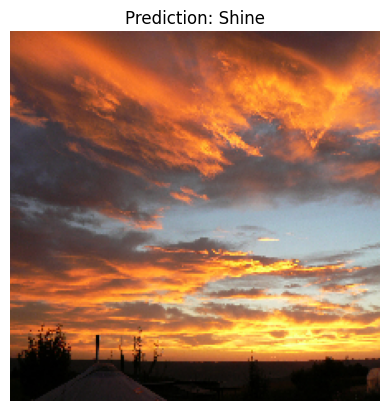

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

model = load_model("resnet50_weather.h5")

img = cv2.imread("/content/Multi-class Weather Dataset/Sunrise/sunrise10.jpg")
img = cv2.resize(img, (224,224))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_input = np.array([img_rgb]) / 255.0

pred = model.predict(img_input)
class_id = np.argmax(pred)
confidence = pred[0][class_id]



class_names = ["Cloudy", "Rain", "Shine", "Sunrise"]

print("\nPredicted Weather:", class_names[class_id])
print("Confidence:", confidence)

plt.imshow(img_rgb)
plt.title(f"Prediction: {class_names[class_id]}")
plt.axis("off")
plt.show()

In [ ]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import tensorflow as tf


model = tf.keras.models.load_model("resnet50_weather.h5")


test_path = "/content/Multi-class Weather Dataset"


classes = ["Cloudy", "Rain", "Shine", "Sunrise"]

total_images = 0
total_correct = 0

for cls in classes:
    folder = os.path.join(test_path, cls)
    correct = 0
    count = 0

    print(f"\n--- ResNet50 Predicting folder: {cls} ---")

    for filename in os.listdir(folder):
        img_path = os.path.join(folder, filename)


        img = load_img(img_path, target_size=(224, 224))
        img = img_to_array(img) / 255.0
        img = np.expand_dims(img, axis=0)

        pred = model.predict(img, verbose=0)
        pred_class = classes[np.argmax(pred)]

        count += 1
        total_images += 1

        if pred_class == cls:
            correct += 1
            total_correct += 1

        print(f"{filename} → {pred_class}")

    folder_acc = correct / count * 100
    print(f"Accuracy for {cls}: {folder_acc:.2f}%")

overall_acc = total_correct / total_images * 100
print(f"\n=== OVERALL RESNET50 ACCURACY: {overall_acc:.2f}% ===")


--- ResNet50 Predicting folder: Cloudy ---
cloudy215.jpg → Sunrise
cloudy197.jpg → Sunrise
cloudy178.jpg → Sunrise
cloudy216.jpg → Sunrise
cloudy210.jpg → Sunrise
cloudy32.jpg → Sunrise
cloudy74.jpg → Sunrise
cloudy182.jpg → Sunrise
cloudy275.jpg → Sunrise
cloudy271.jpg → Sunrise
cloudy3.jpg → Sunrise
cloudy160.jpg → Sunrise
cloudy296.jpg → Sunrise
cloudy202.jpg → Sunrise
cloudy144.jpg → Sunrise
cloudy229.jpg → Sunrise
cloudy228.jpg → Sunrise
cloudy294.jpg → Sunrise
cloudy285.jpg → Sunrise
cloudy148.jpg → Sunrise
cloudy2.jpg → Sunrise
cloudy288.jpg → Sunrise
cloudy258.jpg → Sunrise
cloudy227.jpg → Sunrise
cloudy170.jpg → Sunrise
cloudy248.jpg → Sunrise
cloudy5.jpg → Sunrise
cloudy39.jpg → Sunrise
cloudy121.jpg → Sunrise
cloudy54.jpg → Sunrise
cloudy60.jpg → Sunrise
cloudy143.jpg → Sunrise
cloudy69.jpg → Sunrise
cloudy235.jpg → Sunrise
cloudy78.jpg → Sunrise
cloudy151.jpg → Sunrise
cloudy104.jpg → Sunrise
cloudy48.jpg → Sunrise
cloudy171.jpg → Sunrise
cloudy33.jpg → Sunrise
cloudy196.j

In [ ]:
import os
import shutil
import time
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BASE_PATH = "/content/Multi-class Weather Dataset"

for root, dirs, files in os.walk(BASE_PATH):
    if ".ipynb_checkpoints" in dirs:
        shutil.rmtree(os.path.join(root, ".ipynb_checkpoints"))

TRAIN_PATH = os.path.join(BASE_PATH, "train")
VAL_PATH = os.path.join(BASE_PATH, "val")

IMG_SIZE = (224,224)
BATCH_SIZE = 16
EPOCHS = 15

datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True
)

train_gen = datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_gen = datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

NUM_CLASSES = train_gen.num_classes

resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

resnet.trainable = False

model = Sequential([
    resnet,
    Flatten(),
    Dense(256, activation="relu"),
    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Classes:", train_gen.class_indices)
print("Total Parameters:", model.count_params())

start_train = time.time()

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)

end_train = time.time()

print("Training Time (sec):", round(end_train-start_train,2))

model.save("resnet50_weather.h5")

print("Model Saved")

Found 1125 images belonging to 4 classes.
Found 1125 images belonging to 4 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Classes: {'Cloudy': 0, 'Rain': 1, 'Shine': 2, 'Sunrise': 3}
Total Parameters: 49279108
Epoch 1/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 66s 744ms/step - accuracy: 0.3582 - loss: 3.1754 - val_accuracy: 0.3120 - val_loss: 1.5932
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 41s 577ms/step - accuracy: 0.4276 - loss: 1.2617 - val_accuracy: 0.5484 - val_loss: 1.0099
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 565ms/step - accuracy: 0.5253 - loss: 1.0908 - val_accuracy: 0.5671 - val_loss: 0.9133
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 570ms/step - accuracy: 0.5956 - loss: 0.9302 - val_accuracy: 0.7600 - val_loss: 0.8016
Epoch 5/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 567ms/step - accuracy: 0.6267 - loss: 0.9088 - val_accuracy: 0.6844 - val_loss: 0.8557
Epoch 6/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 40s 563ms/step - accuracy: 0.6089 - loss: 0.9167 - val_accuracy: 0.6329 - val_loss: 0.8739
Epoc

Training Time (sec): 622.09
Model Saved


Total Parameters: 49279108

--- ResNet50 Predicting Folder: Cloudy ---
cloudy104.jpg -> Cloudy
cloudy142.jpg -> Cloudy
cloudy214.jpg -> Rain
cloudy38.jpg -> Rain
cloudy63.jpg -> Cloudy
cloudy123.jpg -> Cloudy
cloudy64.jpg -> Rain
cloudy292.jpg -> Cloudy
cloudy181.jpg -> Sunrise
cloudy20.jpg -> Rain
cloudy145.jpg -> Cloudy
cloudy14.jpg -> Cloudy
cloudy274.jpg -> Cloudy
cloudy267.jpg -> Rain
cloudy288.jpg -> Rain
cloudy245.jpg -> Cloudy
cloudy194.jpg -> Rain
cloudy32.jpg -> Cloudy
cloudy101.jpg -> Rain
cloudy252.jpg -> Cloudy
cloudy154.jpg -> Cloudy
cloudy66.jpg -> Cloudy
cloudy238.jpg -> Cloudy
cloudy289.jpg -> Sunrise
cloudy23.jpg -> Cloudy
cloudy79.jpg -> Cloudy
cloudy36.jpg -> Cloudy
cloudy177.jpg -> Rain
cloudy138.jpg -> Cloudy
cloudy56.jpg -> Cloudy
cloudy218.jpg -> Cloudy
cloudy143.jpg -> Cloudy
cloudy24.jpg -> Rain
cloudy184.jpg -> Rain
cloudy170.jpg -> Cloudy
cloudy258.jpg -> Cloudy
cloudy94.jpg -> Rain
cloudy162.jpg -> Cloudy
cloudy114.jpg -> Cloudy
cloudy120.jpg -> Rain
cloudy

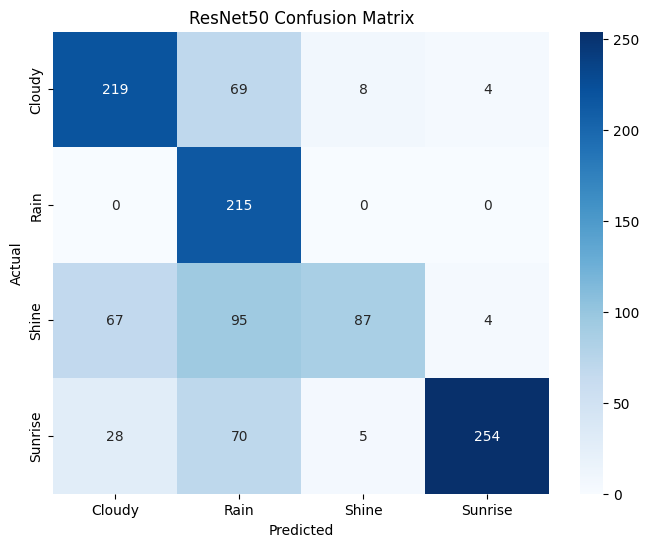

In [ ]:
import os
import shutil
import time
import numpy as np
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

BASE_PATH = "/content/Multi-class Weather Dataset"

for root, dirs, files in os.walk(BASE_PATH):
    if ".ipynb_checkpoints" in dirs:
        shutil.rmtree(os.path.join(root, ".ipynb_checkpoints"))

TEST_PATH = os.path.join(BASE_PATH, "test")

model = tf.keras.models.load_model("resnet50_weather.h5")

print("Total Parameters:", model.count_params())

classes = ["Cloudy", "Rain", "Shine", "Sunrise"]

y_true = []
y_pred = []

total_images = 0
total_correct = 0

start_inference = time.time()

for cls in classes:

    folder = os.path.join(TEST_PATH, cls)

    correct = 0
    count = 0

    print(f"\n--- ResNet50 Predicting Folder: {cls} ---")

    for filename in os.listdir(folder):

        img_path = os.path.join(folder, filename)

        img = load_img(img_path, target_size=(224,224))
        img = img_to_array(img) / 255.0
        img = np.expand_dims(img, axis=0)

        pred = model.predict(img, verbose=0)

        pred_class = classes[np.argmax(pred)]

        y_true.append(cls)
        y_pred.append(pred_class)

        count += 1
        total_images += 1

        if pred_class == cls:
            correct += 1
            total_correct += 1

        print(f"{filename} -> {pred_class}")

    folder_acc = (correct / count) * 100

    print(f"Accuracy for {cls}: {folder_acc:.2f}%")

end_inference = time.time()

print("\nInference Time (seconds):", round(end_inference-start_inference,2))

overall_acc = (total_correct / total_images) * 100

print("\nOverall Accuracy:", round(overall_acc,2), "%")

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix")

plt.show()